# 1 — Construct and audit a pseudopopulation
Fresh source-level computation. Public default: invented three-landmark/six-pair data. Supplied-data mode uses an explicit protected manifest and requires independent execution approval. No model fitting.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from neuro.notebook_inputs import configuration_from_environment, inspect_inputs, load_inputs, effective_pair_map
from neuro.pseudopopulation import sample_plan, materialize, support
from neuro.notebook_artifacts import ArtifactStore, FitAccounting, target_heads, write_private_json, verify_artifacts, runtime_identity, validate_kernel_identity
from neuro.notebook_support import workspace, usage_summary, source_budget, checked_assemblies, compact_metrics, plot_confusions

configuration = configuration_from_environment()
settings = configuration['execution']
output = workspace()
def private_warning(message, category, filename, lineno, file=None, line=None):
    # Preserve full provenance privately; do not render host paths in shared figures/output.
    warning_path = output / 'warnings-private.jsonl'
    with warning_path.open('a') as handle:
        handle.write(json.dumps({'message': str(message), 'category': category.__name__, 'filename': filename, 'lineno': lineno}) + '\n')
    warning_path.chmod(0o600)
    print(category.__name__ + ': ' + str(message), file=sys.stderr)
warnings.showwarning = private_warning
store = ArtifactStore(output / 'artifacts')
store.save('configuration', configuration)
store.save('kernel_runtime_before_inputs', validate_kernel_identity(configuration))
print('Input mode:', configuration['mode'], '| exploratory computational assay; no biological IID inference')

Input mode: invented | exploratory computational assay; no biological IID inference


## Explicit metadata and target boundary
Authenticate only supplied files, regenerate eligibility/assignments, freeze the contributor embargo and complete-support panel before neural interpretation. The public default is invented data. Missing supplied inputs fail; no demo or historical-result fallback.

In [2]:
inspection = inspect_inputs(configuration)  # Metadata/hash step only for supplied inputs.
store.save('metadata_selection', inspection)  # Protected provenance; never displayed.
print(json.dumps(inspection.audit, sort_keys=True))
assert inspection.audit['contributor_overlap'] == 0
assert inspection.audit['selected_train'] > 0 and inspection.audit['selected_development'] > 0

{"access": "invented fixture; no biological input files", "contributor_overlap": 0, "eligible": 216, "embargo_removed_train": 0, "exclusion_counts": {}, "original_development": 72, "original_sessions": 3, "original_train": 144, "original_units": 9, "selected_development": 72, "selected_sessions": 3, "selected_train": 144, "selected_units": 9, "surviving_train": 144}


## A worked target derivation
Previous/current successful adjacent-trial marker digits give provisional start/goal. The adapter checks multimodal triplets, importer agreement, QC and eligibility. Only a pseudonymous worked example is printed; the full joined derivation/exclusions remain protected.

In [3]:
example = inspection.selected[0]
worked = {'example': 'source_example', 'previous_marker_digit': example['start'], 'current_marker_digit': example['goal'],
          'derived_pair': f"{example['start']}->{example['goal']}", 'status': 'derived/provisional, not independently measured truth'}
print(json.dumps(worked))
assert worked['derived_pair'] == example['condition']
print('Exclusion waterfall:', json.dumps(inspection.audit['exclusion_counts'], sort_keys=True))

{"example": "source_example", "previous_marker_digit": 1, "current_marker_digit": 2, "derived_pair": "1->2", "status": "derived/provisional, not independently measured truth"}
Exclusion waterfall: {}


## Fresh neural measurements, observation and exposure
The real adapter gates exact source/unit identities before interpreting numeric fields, rejects duplicates/invalid windows, checks full-window counts against events, and freshly bins with the maintained half-open rule. Sequential gzip traversal and whole-file hashing are disclosed, not called physical non-reading.

In [4]:
data, neural_audit = load_inputs(inspection)  # Supplied neural path remains explicitly review-gated.
store.save('source_data', data)
store.save('neural_audit', neural_audit)
print(json.dumps(neural_audit, sort_keys=True))
assert np.isfinite(data.values[data.observed]).all()
assert np.isnan(data.values[~data.observed]).all()
assert not data.dependency_audit()['overlapping_contributor_ids']
print('Source × unit × bin shape:', data.values.shape, '| units:', data.value_unit, '| clock units:', data.time_unit)

{"access": "fresh invented count generation", "full_exposure": true, "observed_values": 2592, "unavailable_values": 5184}
Source × unit × bin shape: (216, 9, 4) | units: count | clock units: s


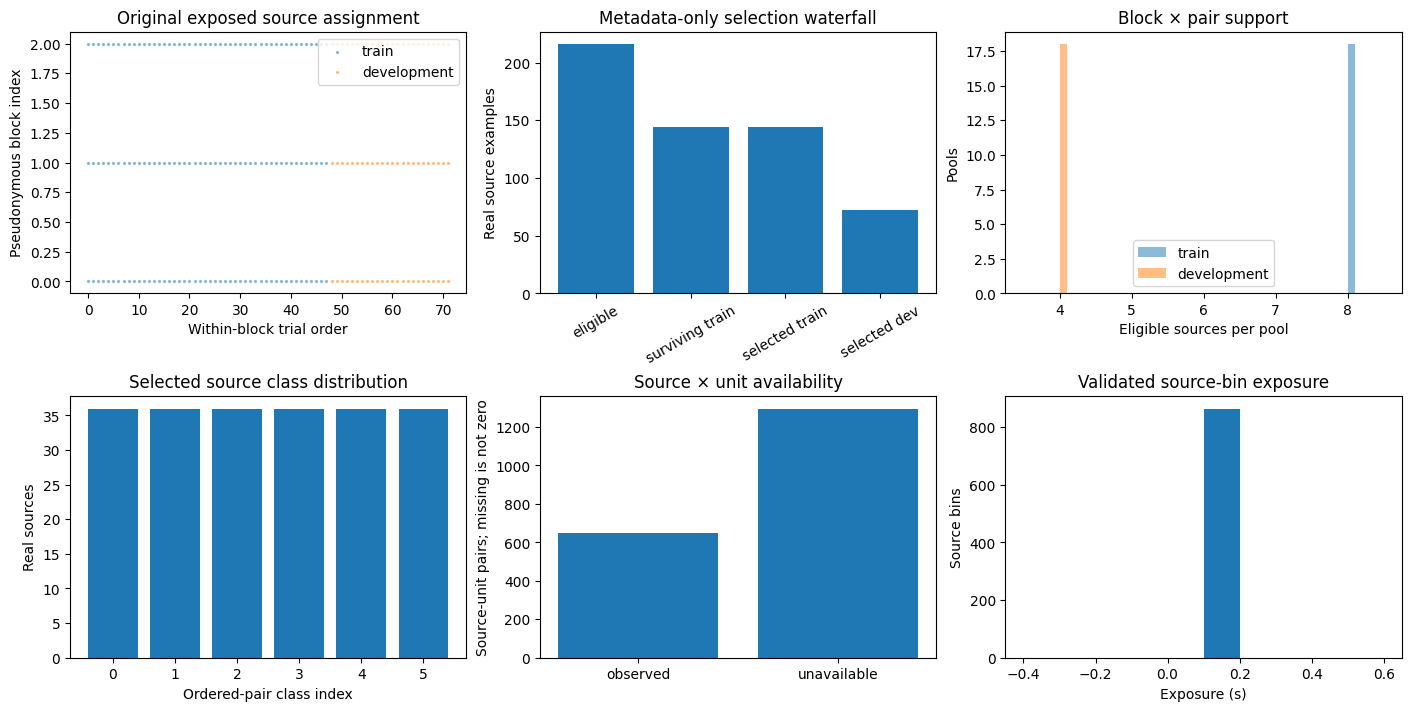

Selected block×condition×split support: min/max 4 8


In [5]:
from neuro.notebook_support import plot_input_audit
fig = plot_input_audit(inspection, data, neural_audit)
display(fig); plt.close(fig)
print('Selected block×condition×split support: min/max', min(r['source_count'] for r in support(data)), max(r['source_count'] for r in support(data)))

## An intact assembled row and exact reconstruction
One source block supplies all of that block’s units and bins. Unit order is preserved. Plans bind observed input bytes separately from effective conditions. All ID-bearing lineage is saved privately.

Constructed rows: 48 | intact blocks per row: 3
First row aliases: {'block_01': 'contributing_source', 'block_02': 'contributing_source', 'block_03': 'contributing_source'}


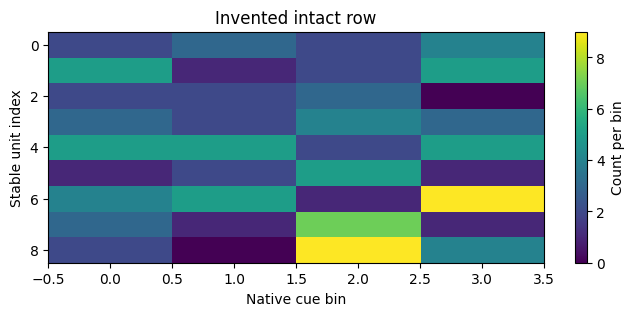

In [6]:
effective = effective_pair_map(data, permutation_seed=None)
plan = sample_plan(data, split_id='train', rows_per_condition=settings['train_rows_per_condition'], seed=0, effective_conditions=effective)
assembly = materialize(data, plan)
reconstructed = materialize(data, assembly.plan)
np.testing.assert_array_equal(assembly.values, reconstructed.values)
np.testing.assert_array_equal(assembly.targets, reconstructed.targets)
store.save('construction_assembly', assembly)
print('Constructed rows:', len(plan.rows), '| intact blocks per row:', len(data.block_ids))
print('First row aliases:', {f'block_{i+1:02d}': 'contributing_source' for i in range(len(data.block_ids))})
fig, ax = plt.subplots(figsize=(8, 3))
illustration = assembly.values[0] if configuration['mode'] == 'invented' else np.nanmean(data.values, axis=0)
image = ax.imshow(illustration, aspect='auto'); fig.colorbar(image, ax=ax, label='Count per bin' if configuration['mode'] == 'invented' else 'Mean count per bin')
ax.set(xlabel='Native cue bin', ylabel='Stable unit index', title='Invented intact row' if configuration['mode'] == 'invented' else 'Aggregate unit/bin means across selected sources')
display(fig); plt.close(fig)

## Eligible / used / unused / repeated source accounting
The constructed-row count is not an independent biological sample size.

{"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 49, "1": 54, "2": 34, "3": 6, "4": 1}, "unused_sources": 49, "used_sources": 95}


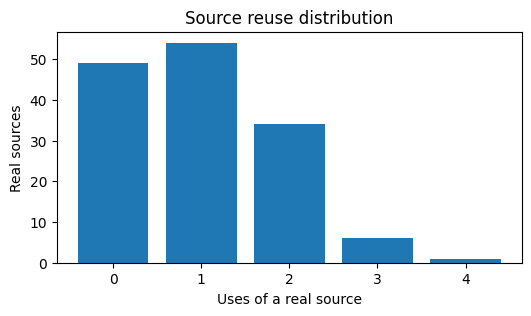

In [7]:
usage = usage_summary(data, assembly)
print(json.dumps(usage, sort_keys=True))
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(list(usage['reuse_histogram']), list(usage['reuse_histogram'].values()))
ax.set(xlabel='Uses of a real source', ylabel='Real sources', title='Source reuse distribution')
display(fig); plt.close(fig)
accounting = FitAccounting().start()

## Interpretation limits
These are source-safe conditional pseudopopulations, not simultaneous trials. Matching uses known labels; this is not an unknown-trial prediction pipeline. Bins, synthetic rows and computational seeds are dependent. Place-selected units, provisional marker meaning, inherited preprocessing and historical exposure remain limitations. Contributor separation does not remove long-range serial/session confounds. No biological confidence intervals, p-values, mechanism, dynamics or prospective-path claim follows from these figures. The permutation diagnostic is alignment-breaking, not a biological exchangeability test.

In [8]:
fit_counts = accounting.stop()
store.save('kernel_runtime_final', runtime_identity())
expected_counts = {'pca': 0, 'logistic': 0, 'lda': 0, 'cebra': 0, 'optimizer_updates': 0}
manifest_hash = store.finish(fit_counts=fit_counts, expected_counts=expected_counts)
replay = verify_artifacts(output / 'artifacts', expected_manifest_hash=manifest_hash)
write_private_json(output / 'completion.json', {'manifest_sha256': manifest_hash, 'fit_counts': fit_counts, 'replay': replay})
print(json.dumps(replay, sort_keys=True))
assert replay['status'] == 'fit-blocked-loaded-model-replay-passed'

{"fit_counts": {"cebra": 0, "lda": 0, "logistic": 0, "optimizer_updates": 0, "pca": 0}, "manifest_sha256": "31cf1d1203f63ad1a1f714f07fd7ea832fa866b843757ae4c23c918efb608968", "readout_splits_checked": 0, "status": "fit-blocked-loaded-model-replay-passed"}
